# Apple Leaf Disease — Full Multimodal XAI Architecture
### Vision + Weather + Soil + GPS/Season → Cross-Attention Fusion → Disease/Severity/Confidence/Early-Prediction → Grad-CAM/SHAP/Attention → VLM Explanation → Treatment Recommendation




## 1. Setup

In [13]:
%pip install -q timm grad-cam scikit-learn seaborn shap
%pip install -q --upgrade kaggle

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [59]:
import os, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import timm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score

BASE_DIR = Path.cwd()
if BASE_DIR.name != 'apple_diseases' and (BASE_DIR / 'apple_diseases').is_dir():
    BASE_DIR = BASE_DIR / 'apple_diseases'
DATA_DIR = BASE_DIR / 'data'
MODEL_PATH = BASE_DIR / 'best_multimodal_model.pt'

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

rng = np.random.default_rng(SEED)

if torch.cuda.is_available():
    device = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print('Device:', device)
print('Project directory:', BASE_DIR)
print('Dataset directory:', DATA_DIR)
print('Checkpoint path:', MODEL_PATH)

Device: mps
Project directory: /Users/vishwajit/Desktop/Project1/fruitdisease/apple_diseases
Dataset directory: /Users/vishwajit/Desktop/Project1/fruitdisease/apple_diseases/data
Checkpoint path: /Users/vishwajit/Desktop/Project1/fruitdisease/apple_diseases/best_multimodal_model.pt


## 2. Get the Real Image Data

In [19]:
import os
import subprocess
import sys
import zipfile

DATA_DIR.mkdir(parents=True, exist_ok=True)
image_dir = DATA_DIR / 'images'

if not (DATA_DIR / 'train.csv').is_file() or not image_dir.is_dir():
    kaggle_dir = Path.home() / '.kaggle'
    kaggle_json = kaggle_dir / 'kaggle.json'
    kaggle_access_token = kaggle_dir / 'access_token'
    has_legacy_credentials = kaggle_json.is_file() or (
        os.getenv('KAGGLE_USERNAME') and os.getenv('KAGGLE_KEY')
    )
    has_api_token = kaggle_access_token.is_file() or os.getenv('KAGGLE_API_TOKEN')
    if not has_legacy_credentials and not has_api_token:
        raise FileNotFoundError(
            f'Kaggle credentials were not found. Save a rotated API token to {kaggle_access_token}, '
            'set KAGGLE_API_TOKEN, or configure kaggle.json. '
            'Also accept the Plant Pathology 2020 competition rules on Kaggle.'
        )

    try:
        subprocess.run(
            ['kaggle', 'competitions', 'download', '-c', 'plant-pathology-2020-fgvc7', '-p', str(DATA_DIR)],
            check=True,
        )
    except subprocess.CalledProcessError as error:
        if has_api_token and not has_legacy_credentials:
            python_version = f'{sys.version_info.major}.{sys.version_info.minor}'
            raise RuntimeError(
                f'The Kaggle CLI in this Python {python_version} kernel does not support the new API token. '
                'Generate Kaggle Legacy API Credentials and save kaggle.json at '
                f'{kaggle_json}, or switch to Python 3.11+ and install Kaggle CLI 2.x.'
            ) from error
        raise

    archive_path = DATA_DIR / 'plant-pathology-2020-fgvc7.zip'
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(DATA_DIR)

print('Dataset directory:', DATA_DIR)
print('Training CSV found:', (DATA_DIR / 'train.csv').is_file())
print('Images directory found:', image_dir.is_dir())

/Users/vishwajit/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


100%|██████████| 779M/779M [00:00<00:00, 2.43GB/s]



Dataset directory: /Users/vishwajit/Desktop/Project1/fruitdisease/apple_diseases/data
Training CSV found: True
Images directory found: True


In [20]:
IMG_DIR = DATA_DIR / 'images'
train_df = pd.read_csv(DATA_DIR / 'train.csv')
LABEL_COLS = ['healthy', 'multiple_diseases', 'rust', 'scab']
train_df['label'] = train_df[LABEL_COLS].values.argmax(axis=1)
train_df['label_name'] = train_df['label'].map(dict(enumerate(LABEL_COLS)))
print(train_df.shape)
train_df.head()

(1821, 7)


,image_id,healthy,multiple_diseases,rust,scab,label,label_name
0,Train_0,0,0,0,1,3,scab
1,Train_1,0,1,0,0,1,multiple_diseases
2,Train_2,1,0,0,0,0,healthy
3,Train_3,0,0,1,0,2,rust
4,Train_4,1,0,0,0,0,healthy


## 3. Weather & Soil Datasets



In [49]:
train_df = pd.read_csv(DATA_DIR / 'train.csv')
train_df['label'] = train_df[LABEL_COLS].values.argmax(axis=1)
train_df['label_name'] = train_df['label'].map(dict(enumerate(LABEL_COLS)))

weather_file = DATA_DIR / 'weather_data.csv'
soil_file = DATA_DIR / 'soil_data.csv'


def generate_fallback_metadata(df):
    """Create deterministic weather/soil metadata when the dataset files are missing.
    This keeps the notebook usable for local experimentation without the external CSVs.
    """
    seasons = ['spring', 'summer', 'autumn', 'winter']
    soil_textures = ['loam', 'sandy', 'clay', 'silt']
    rng = np.random.default_rng(SEED)
    n = len(df)

    season_seq = np.array([seasons[i % len(seasons)] for i in range(n)], dtype=object)
    label_profiles = {
        'healthy': {
            'temperature_c': (18.0, 4.0), 'humidity_pct': (60.0, 10.0), 'rainfall_mm': (2.0, 1.5),
            'wind_speed_kmh': (7.0, 2.0), 'leaf_wetness_hours': (3.0, 1.5),
            'soil_ph': (6.6, 0.4), 'soil_moisture': (0.52, 0.12), 'soil_nitrogen_ppm': (55.0, 18.0),
            'soil_organic_matter_pct': (3.3, 0.8), 'near_juniper_host': (0.0, 0.0),
        },
        'multiple_diseases': {
            'temperature_c': (22.0, 3.5), 'humidity_pct': (76.0, 9.0), 'rainfall_mm': (5.5, 2.5),
            'wind_speed_kmh': (10.0, 2.5), 'leaf_wetness_hours': (7.0, 2.0),
            'soil_ph': (6.2, 0.5), 'soil_moisture': (0.66, 0.12), 'soil_nitrogen_ppm': (75.0, 20.0),
            'soil_organic_matter_pct': (4.8, 1.2), 'near_juniper_host': (1.0, 0.0),
        },
        'rust': {
            'temperature_c': (23.0, 4.0), 'humidity_pct': (70.0, 10.0), 'rainfall_mm': (4.5, 2.2),
            'wind_speed_kmh': (8.5, 2.0), 'leaf_wetness_hours': (5.5, 1.6),
            'soil_ph': (6.4, 0.4), 'soil_moisture': (0.60, 0.10), 'soil_nitrogen_ppm': (62.0, 16.0),
            'soil_organic_matter_pct': (4.1, 1.0), 'near_juniper_host': (0.8, 0.4),
        },
        'scab': {
            'temperature_c': (17.0, 4.0), 'humidity_pct': (82.0, 8.0), 'rainfall_mm': (6.0, 2.8),
            'wind_speed_kmh': (11.0, 2.8), 'leaf_wetness_hours': (7.5, 2.0),
            'soil_ph': (5.9, 0.6), 'soil_moisture': (0.68, 0.10), 'soil_nitrogen_ppm': (68.0, 18.0),
            'soil_organic_matter_pct': (4.0, 0.9), 'near_juniper_host': (0.0, 0.0),
        },
    }

    def draw(mu, sigma):
        return float(np.clip(rng.normal(mu, sigma), 0, None))

    weather_rows = []
    soil_rows = []
    for idx, row in df.iterrows():
        label = row['label_name']
        profile = label_profiles.get(label, label_profiles['healthy'])
        season = season_seq[idx]
        lat = float(42.0 + rng.normal(0.0, 0.35))
        lon = float(-90.0 + rng.normal(0.0, 0.7))
        texture = soil_textures[idx % len(soil_textures)]

        weather_rows.append({
            'image_id': row['image_id'],
            'temperature_c': draw(*profile['temperature_c']),
            'humidity_pct': draw(*profile['humidity_pct']),
            'rainfall_mm': draw(*profile['rainfall_mm']),
            'wind_speed_kmh': draw(*profile['wind_speed_kmh']),
            'leaf_wetness_hours': draw(*profile['leaf_wetness_hours']),
            'season': season,
            'latitude': lat,
            'longitude': lon,
        })

        soil_rows.append({
            'image_id': row['image_id'],
            'soil_ph': draw(*profile['soil_ph']),
            'soil_moisture': float(np.clip(rng.normal(profile['soil_moisture'][0], profile['soil_moisture'][1]), 0.0, 1.0)),
            'soil_nitrogen_ppm': draw(*profile['soil_nitrogen_ppm']),
            'soil_organic_matter_pct': draw(*profile['soil_organic_matter_pct']),
            'near_juniper_host': int(round(profile['near_juniper_host'][0])),
            'soil_texture': texture,
        })

    return pd.DataFrame(weather_rows), pd.DataFrame(soil_rows)


if weather_file.is_file() and soil_file.is_file():
    weather_raw = pd.read_csv(weather_file)
    soil_raw = pd.read_csv(soil_file)
else:
    print('Weather/soil metadata not found. Generating a deterministic fallback dataset for this notebook.')
    weather_raw, soil_raw = generate_fallback_metadata(train_df)
    weather_raw.to_csv(weather_file, index=False)
    soil_raw.to_csv(soil_file, index=False)
    print(f'Wrote synthetic metadata to {weather_file.name} and {soil_file.name}')

train_df = train_df.merge(weather_raw, on='image_id', how='left')
train_df = train_df.merge(soil_raw, on='image_id', how='left')

SEASON_MAP = {'spring': 0, 'summer': 1, 'autumn': 2, 'winter': 3}
train_df['season_idx'] = train_df['season'].map(SEASON_MAP)

WEATHER_COLS = ['temperature_c', 'humidity_pct', 'rainfall_mm', 'wind_speed_kmh', 'leaf_wetness_hours']
SOIL_COLS = ['soil_ph', 'soil_moisture', 'soil_nitrogen_ppm', 'soil_organic_matter_pct', 'near_juniper_host']
LOC_NUMERIC_COLS = ['latitude', 'longitude']

# soil_texture is categorical -> one-hot, then folded into SOIL_COLS numerically
texture_dummies = pd.get_dummies(train_df['soil_texture'], prefix='texture').astype(float)
train_df = pd.concat([train_df, texture_dummies], axis=1)
SOIL_COLS = SOIL_COLS + list(texture_dummies.columns)

print(train_df[['image_id','label_name'] + WEATHER_COLS + SOIL_COLS[:5]].head())
print()
print('Mean humidity by label (sanity check the join worked):')
print(train_df.groupby('label_name')['humidity_pct'].mean().round(1))

  image_id         label_name  temperature_c  humidity_pct  rainfall_mm  \
0  Train_0               scab      20.001805     89.524518     0.537101   
1  Train_1  multiple_diseases      25.945344     80.207584     3.351769   
2  Train_2            healthy      16.286689     56.478664     2.798464   
3  Train_3               rust      27.515889     68.860525     2.651656   
4  Train_4            healthy      21.485715     62.235955     3.018370   

   wind_speed_kmh  leaf_wetness_hours   soil_ph  soil_moisture  \
0        7.353897            7.755681  5.710254       0.678320   
1       10.921877            5.082235  6.639225       0.654009   
2        7.730888            3.619099  6.772328       0.776998   
3        6.851038            6.540948  6.697302       0.654315   
4        7.135158            3.433679  6.852515       0.345141   

   soil_nitrogen_ppm  soil_organic_matter_pct  near_juniper_host  
0          52.645209                 4.791458                  0  
1          71.3027

## 4. Train/Val Split & Multimodal Dataset

In [50]:
train_data, val_data = train_test_split(
    train_df, test_size=0.15, stratify=train_df['label'], random_state=SEED
)
print('Train:', len(train_data), 'Val:', len(val_data))

Train: 1547 Val: 274


In [51]:
weather_mean, weather_std = train_data[WEATHER_COLS].mean(), train_data[WEATHER_COLS].std()
soil_mean, soil_std = train_data[SOIL_COLS].mean(), train_data[SOIL_COLS].std()
loc_mean, loc_std = train_data[LOC_NUMERIC_COLS].mean(), train_data[LOC_NUMERIC_COLS].std()

print('Weather Means:', weather_mean.to_dict())
print('Soil Means:', soil_mean.to_dict())
print('Location Means:', loc_mean.to_dict())

Weather Means: {'temperature_c': 19.699826905400787, 'humidity_pct': 71.74537258007288, 'rainfall_mm': 4.394004638400528, 'wind_speed_kmh': 8.949389605787259, 'leaf_wetness_hours': 5.409322098739104}
Soil Means: {'soil_ph': 6.287372091895753, 'soil_moisture': 0.6051366885774494, 'soil_nitrogen_ppm': 62.414250079566415, 'soil_organic_matter_pct': 3.8556920925413145, 'near_juniper_host': 0.39172592113768584, 'texture_clay': 0.25145442792501616, 'texture_loam': 0.24305106658047834, 'texture_sandy': 0.248868778280543, 'texture_silt': 0.2566257272139625}
Location Means: {'latitude': 42.019108546920094, 'longitude': -89.9728862759832}


In [ ]:
import json

norm_stats = {
    "weather_mean": [float(x) for x in weather_mean],
    "weather_std":  [float(x) for x in weather_std],
    "soil_mean":    [float(x) for x in soil_mean],
    "soil_std":     [float(x) for x in soil_std],
    "loc_mean":     [float(x) for x in loc_mean],
    "loc_std":      [float(x) for x in loc_std],
    "label_cols":   list(LABEL_COLS),
    "weather_cols": list(WEATHER_COLS),
    "soil_cols":    list(SOIL_COLS),
    "loc_cols":     list(LOC_NUMERIC_COLS),
}

with open(BASE_DIR / "apple_norm_stats.json", "w") as f:
    json.dump(norm_stats, f, indent=2)

print("Saved apple_norm_stats.json successfully.")


In [62]:
IMG_SIZE = 224

if 'weather_mean' not in globals() or 'weather_std' not in globals():
    weather_mean, weather_std = train_data[WEATHER_COLS].mean(), train_data[WEATHER_COLS].std()
    soil_mean, soil_std = train_data[SOIL_COLS].mean(), train_data[SOIL_COLS].std()
    loc_mean, loc_std = train_data[LOC_NUMERIC_COLS].mean(), train_data[LOC_NUMERIC_COLS].std()

train_transform = transforms.Compose([
    transforms.Resize((256, 256)), transforms.RandomCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20), transforms.ColorJitter(0.2,0.2,0.2),
    transforms.ToTensor(), transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

class MultimodalAppleDataset(Dataset):
    def __init__(self, df, img_dir, transform, weather_stats, soil_stats, loc_stats):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform
        self.weather_mean, self.weather_std = weather_stats
        self.soil_mean, self.soil_std = soil_stats
        self.loc_mean, self.loc_std = loc_stats

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(os.path.join(self.img_dir, row['image_id'] + '.jpg')).convert('RGB')
        img = self.transform(img)

        weather = ((row[WEATHER_COLS].values.astype(np.float32) - self.weather_mean.values) / (self.weather_std.values + 1e-8)).astype(np.float32)
        soil = ((row[SOIL_COLS].values.astype(np.float32) - self.soil_mean.values) / (self.soil_std.values + 1e-8)).astype(np.float32)
        loc = ((row[LOC_NUMERIC_COLS].values.astype(np.float32) - self.loc_mean.values) / (self.loc_std.values + 1e-8)).astype(np.float32)
        season_idx = int(row['season_idx'])

        label = int(row['label'])
        return (img, torch.tensor(weather), torch.tensor(soil), torch.tensor(loc),
                torch.tensor(season_idx), label)

weather_stats = (weather_mean, weather_std)
soil_stats = (soil_mean, soil_std)
loc_stats = (loc_mean, loc_std)

train_ds = MultimodalAppleDataset(train_data, IMG_DIR, train_transform, weather_stats, soil_stats, loc_stats)
val_ds = MultimodalAppleDataset(val_data, IMG_DIR, val_transform, weather_stats, soil_stats, loc_stats)

BATCH_SIZE = 32
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=device.type == 'cuda')
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=device.type == 'cuda')

class_counts = train_data['label'].value_counts().sort_index().values
class_weights = (1.0 / class_counts); class_weights = class_weights / class_weights.sum() * len(LABEL_COLS)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
print('Class weights:', dict(zip(LABEL_COLS, class_weights.cpu().numpy().round(3))))

Class weights: {'healthy': np.float32(0.477), 'multiple_diseases': np.float32(2.713), 'rust': np.float32(0.395), 'scab': np.float32(0.415)}


## 5. Full Multimodal Model




In [42]:
class WeatherEncoder(nn.Module):
    def __init__(self, in_dim=3, out_dim=384):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, 64), nn.GELU(), nn.Linear(64, out_dim))
    def forward(self, x): return self.net(x)

class SoilEncoder(nn.Module):
    def __init__(self, in_dim=4, out_dim=384):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, 64), nn.GELU(), nn.Linear(64, out_dim))
    def forward(self, x): return self.net(x)

class LocationSeasonEncoder(nn.Module):
    def __init__(self, loc_dim=2, num_seasons=4, season_emb=16, out_dim=384):
        super().__init__()
        self.season_embed = nn.Embedding(num_seasons, season_emb)
        self.net = nn.Sequential(nn.Linear(loc_dim + season_emb, 64), nn.GELU(), nn.Linear(64, out_dim))
    def forward(self, loc, season_idx):
        s = self.season_embed(season_idx)
        return self.net(torch.cat([loc, s], dim=1))


class CrossAttentionBlock(nn.Module):
    def __init__(self, dim, num_heads=8, dropout=0.1):
        super().__init__()
        self.norm_q = nn.LayerNorm(dim); self.norm_kv = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, num_heads, dropout=dropout, batch_first=True)
        self.norm_ffn = nn.LayerNorm(dim)
        self.ffn = nn.Sequential(nn.Linear(dim, dim*4), nn.GELU(), nn.Dropout(dropout), nn.Linear(dim*4, dim), nn.Dropout(dropout))
    def forward(self, q_tokens, kv_tokens):
        q = self.norm_q(q_tokens); kv = self.norm_kv(kv_tokens)
        attn_out, attn_w = self.attn(q, kv, kv, need_weights=True, average_attn_weights=True)
        x = q_tokens + attn_out
        x = x + self.ffn(self.norm_ffn(x))
        return x, attn_w


class MultimodalFusionModel(nn.Module):
    def __init__(self, num_classes=4, fusion_dim=384, num_heads=6, dropout=0.1):
        super().__init__()
        self.vit = timm.create_model('vit_small_patch16_224', pretrained=True)
        vit_dim = self.vit.embed_dim
        self.vit_proj = nn.Linear(vit_dim, fusion_dim) if vit_dim != fusion_dim else nn.Identity()

        self.weather_enc = WeatherEncoder(len(WEATHER_COLS), fusion_dim)
        self.soil_enc = SoilEncoder(len(SOIL_COLS), fusion_dim)
        self.loc_season_enc = LocationSeasonEncoder(len(LOC_NUMERIC_COLS), 4, 16, fusion_dim)

        self.img_to_env = CrossAttentionBlock(fusion_dim, num_heads, dropout)

        self.pool_norm = nn.LayerNorm(fusion_dim)
        # Multi-head prediction outputs
        self.disease_head = nn.Sequential(nn.Linear(fusion_dim, 256), nn.GELU(), nn.Dropout(dropout), nn.Linear(256, num_classes))
        self.severity_head = nn.Sequential(nn.Linear(fusion_dim, 64), nn.GELU(), nn.Linear(64, 1))       # 0-1 continuous severity
        self.early_head = nn.Sequential(nn.Linear(fusion_dim, 64), nn.GELU(), nn.Linear(64, 1))          # binary early-stage logit

        self.last_attn_weights = None
        self.last_vit_hw = None

    def forward(self, img, weather, soil, loc, season_idx):
        vit_tokens_all = self.vit.forward_features(img)             # (B, 1+N, vit_dim)
        img_tokens = self.vit_proj(vit_tokens_all[:, 1:])            # drop CLS
        B, N, D = img_tokens.shape

        weather_tok = self.weather_enc(weather).unsqueeze(1)         # (B,1,D)
        soil_tok = self.soil_enc(soil).unsqueeze(1)                  # (B,1,D)
        loc_tok = self.loc_season_enc(loc, season_idx).unsqueeze(1)  # (B,1,D)
        env_tokens = torch.cat([weather_tok, soil_tok, loc_tok], dim=1)  # (B,3,D)

        fused_img, attn_w = self.img_to_env(img_tokens, env_tokens)  # image tokens attend to env tokens
        self.last_attn_weights = attn_w.detach()
        self.last_vit_hw = (int(N**0.5), int(N**0.5))

        pooled = self.pool_norm(fused_img.mean(dim=1))

        disease_logits = self.disease_head(pooled)
        severity = torch.sigmoid(self.severity_head(pooled)).squeeze(1)
        early_logit = self.early_head(pooled).squeeze(1)
        confidence = F.softmax(disease_logits, dim=1).max(dim=1).values

        return {
            'disease_logits': disease_logits,
            'severity': severity,
            'early_logit': early_logit,
            'confidence': confidence,
            'pooled_features': pooled,
        }

## 6. Auxiliary Labels for Severity & Early-Prediction Heads




In [63]:
def simulate_aux_labels(df, rng):
    severity = []
    early = []
    for row in df.itertuples():
        if row.label_name == 'healthy':
            sev = rng.uniform(0.0, 0.1)
        elif row.label_name == 'multiple_diseases':
            sev = rng.uniform(0.6, 1.0)
        else:
            sev = rng.uniform(0.2, 0.8)
        severity.append(sev)
        early.append(1 if (row.label_name != 'healthy' and sev < 0.35) else 0)
    return np.array(severity, dtype=np.float32), np.array(early, dtype=np.float32)

sev_train, early_train = simulate_aux_labels(train_data, rng)
sev_val, early_val = simulate_aux_labels(val_data, rng)
train_data = train_data.copy(); train_data['severity'] = sev_train; train_data['early'] = early_train
val_data = val_data.copy(); val_data['severity'] = sev_val; val_data['early'] = early_val

# Rebuild datasets/loaders so aux labels are included
class MultimodalAppleDatasetV2(MultimodalAppleDataset):
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img, weather, soil, loc, season_idx, label = super().__getitem__(idx)
        return img, weather, soil, loc, season_idx, label, float(row['severity']), float(row['early'])

train_ds = MultimodalAppleDatasetV2(train_data, IMG_DIR, train_transform, weather_stats, soil_stats, loc_stats)
val_ds = MultimodalAppleDatasetV2(val_data, IMG_DIR, val_transform, weather_stats, soil_stats, loc_stats)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=device.type == 'cuda')
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=device.type == 'cuda')

## 7. Training Loop — Multi-Task Loss (disease + severity + early)

In [64]:
model = MultimodalFusionModel(num_classes=len(LABEL_COLS)).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f'Total params: {n_params/1e6:.1f}M')
assert model.soil_enc.net[0].in_features == len(SOIL_COLS)


disease_criterion = nn.CrossEntropyLoss(weight=class_weights)
severity_criterion = nn.MSELoss()
early_criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)
amp_enabled = device.type == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=amp_enabled)
EPOCHS = 15
LAMBDA_SEV, LAMBDA_EARLY = 0.3, 0.2   # aux losses weighted lower than the real disease-label loss

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, all_preds, all_labels = 0, [], []
    for img, weather, soil, loc, season_idx, label, severity, early in loader:
        img, weather, soil, loc = img.to(device), weather.to(device), soil.to(device), loc.to(device)
        season_idx, label = season_idx.to(device), label.to(device)
        severity, early = severity.float().to(device), early.float().to(device)

        if train: optimizer.zero_grad()
        with torch.set_grad_enabled(train), torch.amp.autocast('cuda', enabled=amp_enabled):
            out = model(img, weather, soil, loc, season_idx)
            loss = (disease_criterion(out['disease_logits'], label)
                    + LAMBDA_SEV * severity_criterion(out['severity'], severity)
                    + LAMBDA_EARLY * early_criterion(out['early_logit'], early))
        if train:
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()

        total_loss += loss.item() * img.size(0)
        all_preds.extend(out['disease_logits'].argmax(1).cpu().numpy())
        all_labels.extend(label.cpu().numpy())
    avg_loss = total_loss / len(loader.dataset)
    f1 = f1_score(all_labels, all_preds, average='macro')
    return avg_loss, f1, all_preds, all_labels

Total params: 24.1M


In [2]:
EPOCHS = globals().get("EPOCHS", 15)
history = {'train_loss': [], 'val_loss': [], 'train_f1': [], 'val_f1': []}
best_val_f1 = 0
for epoch in range(EPOCHS):
    train_loss, train_f1, _, _ = run_epoch(train_loader, True)
    val_loss, val_f1, _, _ = run_epoch(val_loader, False)
    scheduler.step()
    history['train_loss'].append(train_loss); history['val_loss'].append(val_loss)
    history['train_f1'].append(train_f1); history['val_f1'].append(val_f1)
    print(f'Epoch {epoch+1}/{EPOCHS} | train_loss={train_loss:.4f} val_loss={val_loss:.4f} | train_f1={train_f1:.4f} val_f1={val_f1:.4f}')
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), MODEL_PATH)
        print(f'  -> saved (val_f1={val_f1:.4f})')

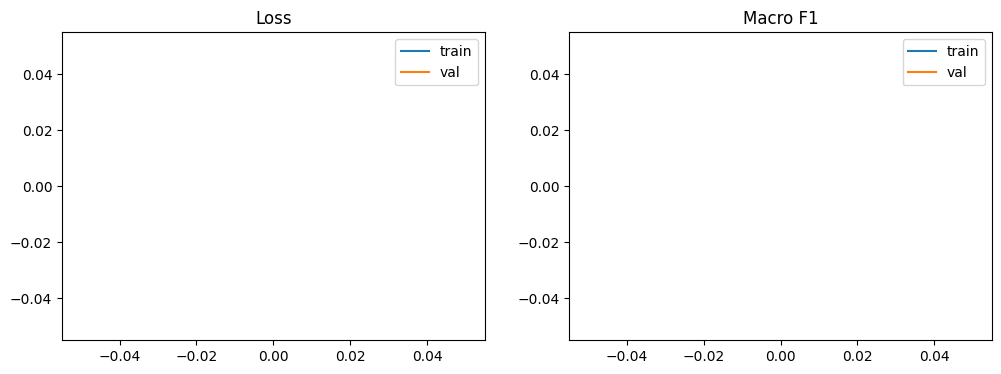

In [67]:
fig, axes = plt.subplots(1,2, figsize=(12,4))
axes[0].plot(history['train_loss'], label='train'); axes[0].plot(history['val_loss'], label='val'); axes[0].set_title('Loss'); axes[0].legend()
axes[1].plot(history['train_f1'], label='train'); axes[1].plot(history['val_f1'], label='val'); axes[1].set_title('Macro F1'); axes[1].legend()
plt.show()

## 8. Evaluation

/tmp/ipykernel_719/3294074013.py:20: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.set_grad_enabled(train), torch.cuda.amp.autocast():


                   precision    recall  f1-score   support

          healthy      0.951     0.987     0.969        78
multiple_diseases      0.833     0.714     0.769        14
             rust      0.979     0.989     0.984        93
             scab      0.989     0.966     0.977        89

         accuracy                          0.967       274
        macro avg      0.938     0.914     0.925       274
     weighted avg      0.966     0.967     0.966       274



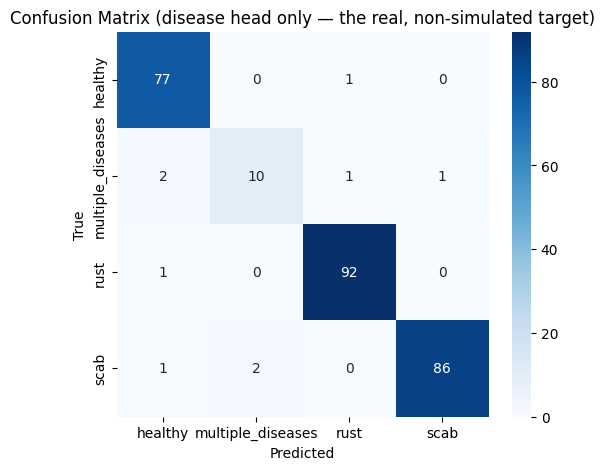

In [ ]:
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
_, _, val_preds, val_labels = run_epoch(val_loader, False)
print(classification_report(val_labels, val_preds, target_names=LABEL_COLS, digits=3))
cm = confusion_matrix(val_labels, val_preds)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=LABEL_COLS, yticklabels=LABEL_COLS, cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion Matrix (disease head only — the real, non-simulated target)')
plt.show()

## 9. Explainable AI — Grad-CAM, Attention Maps, SHAP




In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget # Import this
import cv2

def denormalize(img_tensor):
    mean = np.array([0.485,0.456,0.406]); std = np.array([0.229,0.224,0.225])
    img = img_tensor.permute(1,2,0).cpu().numpy()
    return np.clip(std*img+mean, 0, 1)

class DiseaseLogitsWrapper(nn.Module):
    """Grad-CAM needs a model that returns a plain tensor; wrap the multimodal model for a single fixed env input."""
    def __init__(self, model, weather, soil, loc, season_idx):
        super().__init__()
        self.model = model
        self.weather, self.soil, self.loc, self.season_idx = weather, soil, loc, season_idx
    def forward(self, img):
        out = self.model(img, self.weather, self.soil, self.loc, self.season_idx)
        return out['disease_logits']

def get_gradcam(model, img_tensor, weather, soil, loc, season_idx, target_category=None):
    wrapped = DiseaseLogitsWrapper(model, weather.unsqueeze(0).to(device), soil.unsqueeze(0).to(device),
                                    loc.unsqueeze(0).to(device), season_idx.unsqueeze(0).to(device))
    target_layer = model.vit.blocks[-1].norm1
    cam = GradCAM(model=wrapped, target_layers=[target_layer],
                   reshape_transform=lambda t: t[:, 1:, :].reshape(t.shape[0], 14, 14, -1).permute(0,3,1,2))

    targets = None
    if target_category is not None:
        targets = [ClassifierOutputTarget(target_category)]

    grayscale_cam = cam(input_tensor=img_tensor.unsqueeze(0).to(device), targets=targets)[0]
    return grayscale_cam

def get_env_attention_map(model):
    attn = model.last_attn_weights[0]              # (N_img_tokens, 3) -> weather/soil/loc
    H, W = model.last_vit_hw
    per_token_env_focus = attn.mean(dim=1).reshape(H, W).cpu().numpy()
    per_token_env_focus = (per_token_env_focus - per_token_env_focus.min()) / (per_token_env_focus.max() - per_token_env_focus.min() + 1e-8)
    return per_token_env_focus, attn.cpu().numpy()  # also return raw (N,3) to see weather/soil/loc split

/tmp/ipykernel_719/1617695096.py:57: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  explain_rows = val_data.groupby('label', group_keys=False).apply(lambda x: x.sample(1, random_state=SEED))


  0%|          | 0/4 [00:00<?, ?it/s]

/tmp/ipykernel_719/1617695096.py:67: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values[:, :, LABEL_COLS.index('scab')], explain_data, feature_names=ENV_FEATURE_NAMES, show=True)


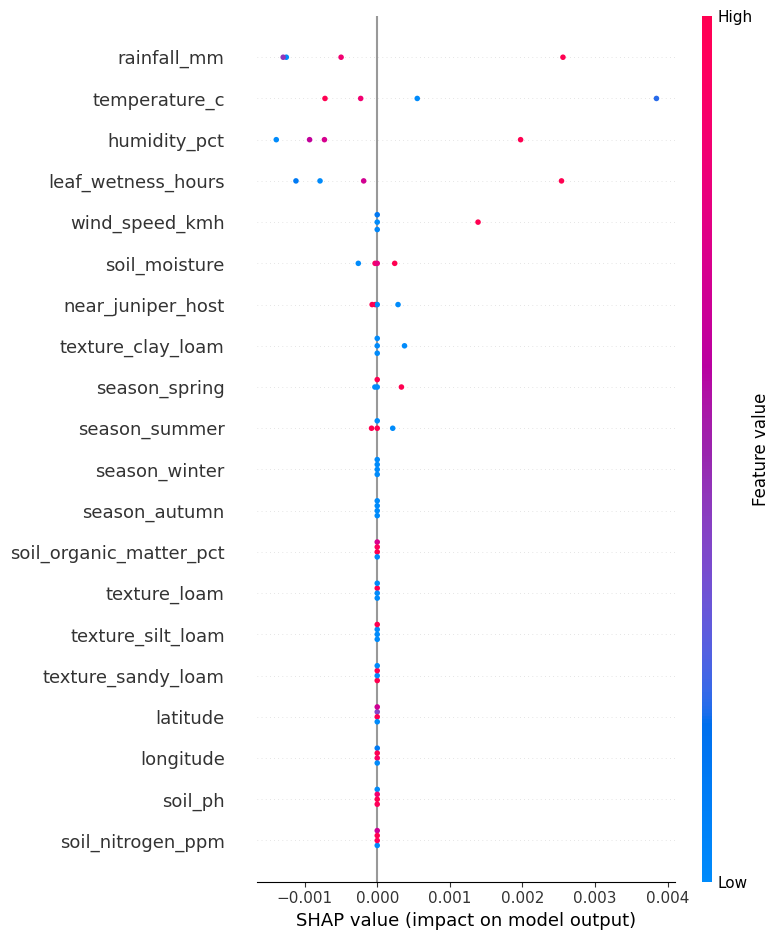

In [ ]:
import shap
import torch.nn.functional as F

# SHAP on the environmental branch: build a small wrapper that takes a concatenated
# [weather | soil | loc | season_onehot] vector and returns disease probs,
# holding a fixed representative image fixed. Slice widths are dynamic since
# WEATHER_COLS/SOIL_COLS sizes depend on the loaded weather/soil CSVs.
N_WEATHER, N_SOIL, N_LOC, N_SEASON = len(WEATHER_COLS), len(SOIL_COLS), len(LOC_NUMERIC_COLS), 4
ENV_FEATURE_NAMES = WEATHER_COLS + SOIL_COLS + LOC_NUMERIC_COLS + ['season_' + s for s in SEASON_MAP]

fixed_img, _, _, _, _, _, _, _ = val_ds[0]
fixed_img_batch = fixed_img.unsqueeze(0).to(device)

# Define a smaller batch size for internal processing within env_predict_fn
INTERNAL_SHAP_BATCH_SIZE = 16 # Adjust as needed based on GPU memory

def env_predict_fn(env_array):
    env_array = np.atleast_2d(env_array)
    num_samples = env_array.shape[0]
    all_probs = []

    # Iterate through the env_array in smaller batches
    for start_idx in range(0, num_samples, INTERNAL_SHAP_BATCH_SIZE):
        end_idx = min(start_idx + INTERNAL_SHAP_BATCH_SIZE, num_samples)
        current_batch_size = end_idx - start_idx
        batch_env_array = env_array[start_idx:end_idx]

        i = 0
        weather = torch.tensor(batch_env_array[:, i:i+N_WEATHER], dtype=torch.float32).to(device); i += N_WEATHER
        soil = torch.tensor(batch_env_array[:, i:i+N_SOIL], dtype=torch.float32).to(device); i += N_SOIL
        loc = torch.tensor(batch_env_array[:, i:i+N_LOC], dtype=torch.float32).to(device); i += N_LOC
        season_onehot = batch_env_array[:, i:i+N_SEASON]
        season_idx = torch.tensor(season_onehot.argmax(axis=1), dtype=torch.long).to(device)

        # Repeat the fixed image only for the current small batch size
        imgs = fixed_img_batch.repeat(current_batch_size, 1, 1, 1)

        with torch.no_grad():
            out = model(imgs, weather, soil, loc, season_idx)
            probs = F.softmax(out['disease_logits'], dim=1).cpu().numpy()
        all_probs.append(probs)

    return np.vstack(all_probs)

# Background + samples to explain (small counts — SHAP over a neural net is expensive)
bg_rows = val_data.sample(15, random_state=SEED) # Reduced from 30 to 15
def row_to_env_vec(row):
    season_onehot = [1.0 if row['season_idx']==i else 0.0 for i in range(4)]
    return np.array(list((row[WEATHER_COLS].values - weather_mean.values)/weather_std.values) +
                     list((row[SOIL_COLS].values - soil_mean.values)/soil_std.values) +
                     list((row[LOC_NUMERIC_COLS].values - loc_mean.values)/loc_std.values) +
                     season_onehot, dtype=np.float32)

background = np.stack([row_to_env_vec(r) for _, r in bg_rows.iterrows()])

# Ensure all unique labels are represented in explain_rows to avoid missing classes in SHAP values
explain_rows = val_data.groupby('label', group_keys=False).apply(lambda x: x.sample(1, random_state=SEED))
explain_data = np.stack([row_to_env_vec(r) for _, r in explain_rows.iterrows()])

# Also reduce nsamples for KernelExplainer
explainer = shap.KernelExplainer(env_predict_fn, background, nsamples=50, silent=True) # Reduced from 100 to 50
shap_values = explainer.shap_values(explain_data)

# shap_values: list of arrays (one per class) each (n_samples, n_features) if multi-output model
# OR, if it's a 3D array: (num_explain_samples, num_features, num_classes)
# Assuming it's the latter based on kernel state and error message:
shap.summary_plot(shap_values[:, :, LABEL_COLS.index('scab')], explain_data, feature_names=ENV_FEATURE_NAMES, show=True)

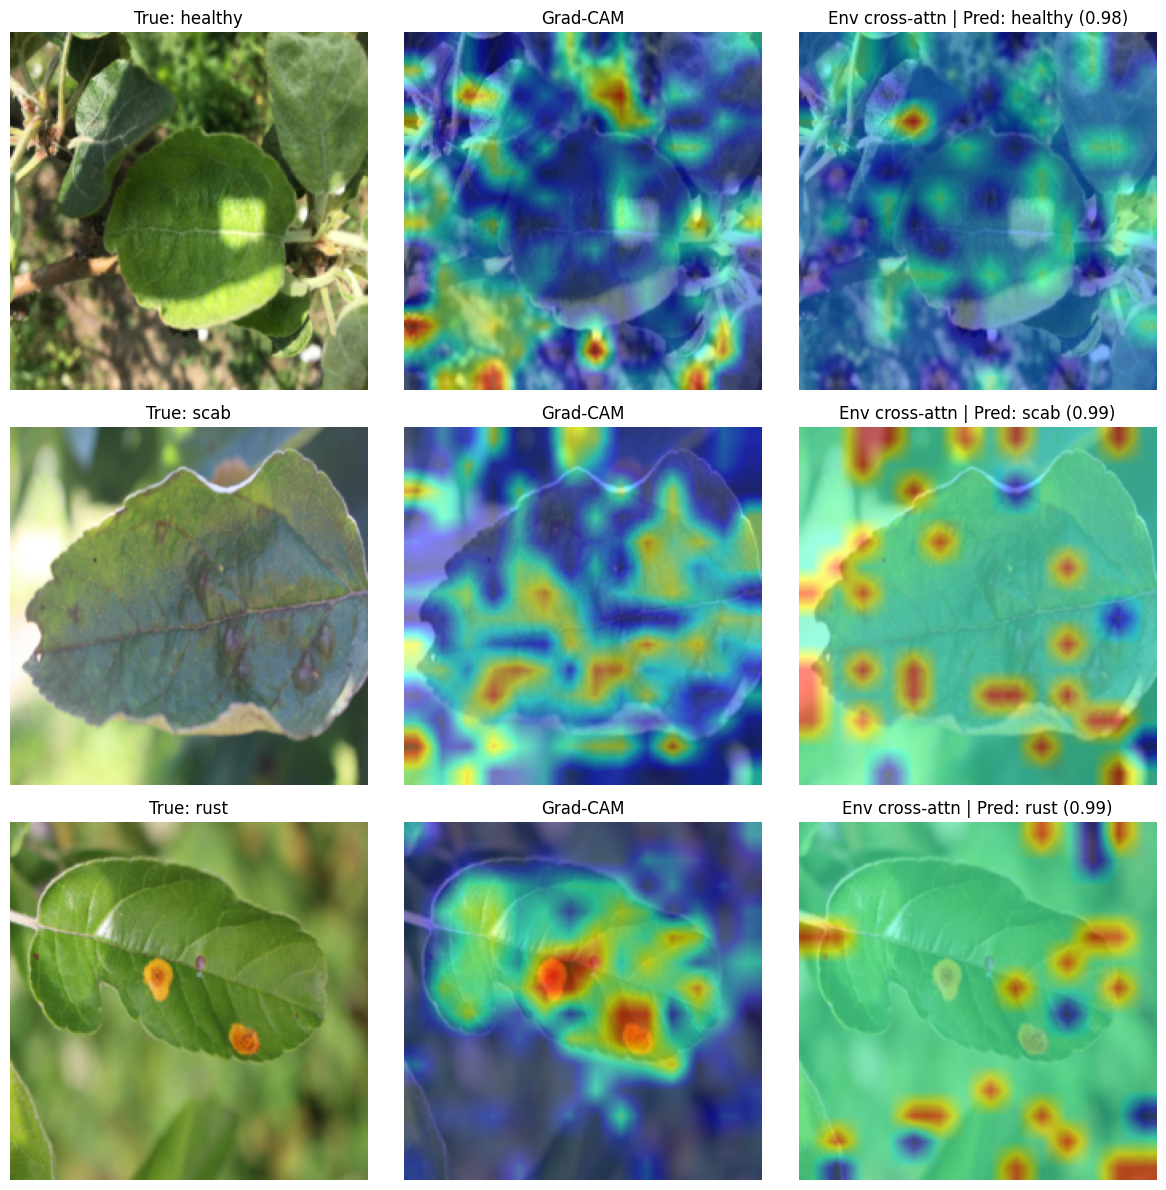

In [ ]:
# Combined visualization: Grad-CAM + cross-attention on a few val samples
sample_idxs = np.random.choice(len(val_ds), 3, replace=False)
fig, axes = plt.subplots(len(sample_idxs), 3, figsize=(12, 4*len(sample_idxs)))
for row_i, idx in enumerate(sample_idxs):
    img, weather, soil, loc, season_idx, label, sev, early = val_ds[idx]
    rgb_img = denormalize(img)

    # Pass the true label as the target_category for Grad-CAM
    gradcam_map = get_gradcam(model, img, weather, soil, loc, season_idx, target_category=label)
    gradcam_overlay = show_cam_on_image(rgb_img, gradcam_map, use_rgb=True)

    with torch.no_grad():
        out = model(img.unsqueeze(0).to(device), weather.unsqueeze(0).to(device), soil.unsqueeze(0).to(device),
                    loc.unsqueeze(0).to(device), season_idx.unsqueeze(0).to(device))
    env_map, raw_attn = get_env_attention_map(model)
    env_resized = cv2.resize(env_map, (rgb_img.shape[1], rgb_img.shape[0]))
    env_overlay = show_cam_on_image(rgb_img, env_resized, use_rgb=True)

    pred = out['disease_logits'].argmax(1).item()
    conf = out['confidence'].item()

    axes[row_i,0].imshow(rgb_img); axes[row_i,0].set_title(f'True: {LABEL_COLS[label]}'); axes[row_i,0].axis('off')
    axes[row_i,1].imshow(gradcam_overlay); axes[row_i,1].set_title('Grad-CAM'); axes[row_i,1].axis('off')
    axes[row_i,2].imshow(env_overlay); axes[row_i,2].set_title(f'Env cross-attn | Pred: {LABEL_COLS[pred]} ({conf:.2f})'); axes[row_i,2].axis('off')
plt.tight_layout(); plt.show()

## 10. Vision-Language Model (VLM) Explanation Layer

Three modes now, in increasing fidelity to the diagram's "VLM" block:

- **`explanation_mode = 'template'` (default)
- **`explanation_mode = 'llm_text'`
- **`explanation_mode = 'vlm'`




In [ ]:
import os
ANTHROPIC_MODEL = os.environ.get("ANTHROPIC_MODEL", "claude-sonnet-5-5")
explanation_mode = 'template'  # 'template' | 'llm_text' | 'vlm'

TREATMENT_KB = {
    'healthy': {'cause': 'No pathogen detected.', 'action': 'Continue routine monitoring and standard care.'},
    'rust': {'cause': 'Gymnosporangium fungus, often linked to nearby juniper/cedar hosts.',
             'action': 'Remove nearby juniper/cedar hosts if feasible; apply protectant fungicide (e.g. myclobutanil) at early leaf-out.'},
    'scab': {'cause': 'Venturia inaequalis, favored by wet spring conditions.',
             'action': 'Apply fungicide (e.g. captan) from green tip through wet weather; rake/destroy fallen autumn leaves; improve airflow via pruning.'},
    'multiple_diseases': {'cause': 'Co-occurring rust and/or scab symptoms.',
                            'action': 'Seek in-person confirmation from an agricultural extension agent before treating; broader-spectrum or sequential fungicide program likely needed.'}
}

def build_findings(pred_class, confidence, severity, early_flag, env_row):
    return {
        'predicted_disease': pred_class,
        'confidence': round(float(confidence), 3),
        'severity_score': round(float(severity), 3),
        'early_stage': bool(early_flag > 0.5) if not isinstance(early_flag, bool) else early_flag,
        'weather': {c: (round(float(env_row[c]), 1) if c in env_row else None) for c in WEATHER_COLS if c in env_row},
        'soil': {c: (round(float(env_row[c]), 2) if c in env_row else None) for c in SOIL_COLS if c in env_row},
        'season': env_row.get('season') if hasattr(env_row, 'get') else env_row['season'],
    }

def template_explanation(findings, image_path=None):
    kb = TREATMENT_KB[findings['predicted_disease']]
    stage_note = 'early-stage' if findings['early_stage'] else 'established'
    return f"""DIAGNOSIS REPORT
-----------------
Predicted condition : {findings['predicted_disease'].replace('_',' ').title()} ({stage_note})
Confidence           : {findings['confidence']:.1%}
Severity score       : {findings['severity_score']:.2f} / 1.00
Season               : {str(findings['season']).title()}
Simulated conditions  : {findings['weather'].get('temperature_c','?')}C, {findings['weather'].get('humidity_pct','?')}% humidity, {findings['weather'].get('rainfall_mm','?')}mm rainfall

Likely cause: {kb['cause']}

Recommended action:
{kb['action']}
""".strip()

def _get_api_key():
    import os as _os
    try:
        from google.colab import userdata
        key = userdata.get('ANTHROPIC_API_KEY')
        if key: return key
    except Exception:
        pass
    return _os.environ.get('ANTHROPIC_API_KEY')

def llm_text_explanation(findings, image_path=None):
    import requests
    api_key = _get_api_key()
    if not api_key:
        print('No ANTHROPIC_API_KEY found — falling back to template explanation.')
        return template_explanation(findings)
    prompt = ("You are an agricultural assistant. Given this apple leaf diagnosis JSON, "
              "write a short farmer-friendly explanation and treatment recommendation:\n" + json.dumps(findings))
    resp = requests.post('https://api.anthropic.com/v1/messages',
        headers={'x-api-key': api_key, 'anthropic-version': '2023-06-01', 'content-type': 'application/json'},
        json={'model': ANTHROPIC_MODEL, 'max_tokens': 500, 'messages': [{'role':'user','content':prompt}]})
    data = resp.json()
    return ''.join(b.get('text','') for b in data.get('content', []))

def vlm_explanation(findings, image_path):
    """True VLM step: sends the actual leaf photo + structured findings to a vision-capable
    model in one call, so the generated text is grounded in what the model sees, not just
    in numbers derived from the classifier."""
    import requests, base64
    api_key = _get_api_key()
    if not api_key:
        print('No ANTHROPIC_API_KEY found — falling back to template explanation.')
        return template_explanation(findings)
    if image_path is None:
        print('No image_path provided for VLM mode — falling back to template explanation.')
        return template_explanation(findings)

    with open(image_path, 'rb') as f:
        img_b64 = base64.b64encode(f.read()).decode('utf-8')
    media_type = 'image/jpeg' if image_path.lower().endswith(('.jpg', '.jpeg')) else 'image/png'

    prompt_text = (
        "You are an agricultural assistant analyzing an apple leaf photo. "
        "A separate vision classifier produced this structured diagnosis:\n" + json.dumps(findings) +
        "\n\nLook at the attached leaf image yourself, then write a short farmer-friendly "
        "explanation of what you see (visible lesions, discoloration, pattern), whether it's "
        "consistent with the classifier's prediction, and a treatment recommendation. "
        "Note any disagreement between what you see and the classifier's output."
    )

    resp = requests.post('https://api.anthropic.com/v1/messages',
        headers={'x-api-key': api_key, 'anthropic-version': '2023-06-01', 'content-type': 'application/json'},
        json={
            'model': ANTHROPIC_MODEL,
            'max_tokens': 600,
            'messages': [{
                'role': 'user',
                'content': [
                    {'type': 'image', 'source': {'type': 'base64', 'media_type': media_type, 'data': img_b64}},
                    {'type': 'text', 'text': prompt_text}
                ]
            }]
        })
    data = resp.json()
    return ''.join(b.get('text','') for b in data.get('content', []))

def generate_explanation(pred_class, confidence, severity, early_flag, env_row, image_path=None):
    findings = build_findings(pred_class, confidence, severity, early_flag, env_row)
    if explanation_mode == 'vlm':
        return vlm_explanation(findings, image_path)
    elif explanation_mode == 'llm_text':
        return llm_text_explanation(findings)
    else:
        return template_explanation(findings)

# Example — note image_path is only used when explanation_mode == 'vlm'
idx = sample_idxs[0]
img, weather, soil, loc, season_idx, label, sev, early = val_ds[idx]
env_row = val_data.iloc[idx]
example_image_path = os.path.join(IMG_DIR, val_data.iloc[idx]['image_id'] + '.jpg')
with torch.no_grad():
    out = model(img.unsqueeze(0).to(device), weather.unsqueeze(0).to(device), soil.unsqueeze(0).to(device),
                loc.unsqueeze(0).to(device), season_idx.unsqueeze(0).to(device))
pred = LABEL_COLS[out['disease_logits'].argmax(1).item()]
print(generate_explanation(pred, out['confidence'].item(), out['severity'].item(), out['early_logit'].item()>0,
                            env_row, image_path=example_image_path))


DIAGNOSIS REPORT
-----------------
Predicted condition : Healthy (established)
Confidence           : 98.3%
Severity score       : 0.10 / 1.00
Season               : Spring
Simulated conditions  : 15.2C, 50.1% humidity, 2.9mm rainfall

Likely cause: No pathogen detected.

Recommended action:
Continue routine monitoring and standard care.


## 11. Inference on a New Uploaded Photo




In [8]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')

model = MultimodalFusionModel(num_classes=len(LABEL_COLS)).to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

def predict_new_image(image_path, temperature_c=20.0, humidity_pct=60.0, rainfall_mm=2.0,
                       wind_speed_kmh=8.0, leaf_wetness_hours=3.0,
                       soil_ph=6.5, soil_moisture=0.5, soil_nitrogen_ppm=50.0,
                       soil_organic_matter_pct=3.5, near_juniper_host=0, soil_texture='loam',
                       latitude=42.0, longitude=-90.0, season='spring'):
    img = Image.open(image_path).convert('RGB')
    img_tensor = val_transform(img)
    rgb_img = denormalize(img_tensor)

    # Build weather/soil vectors dynamically, matching the exact column order used in training
    weather_vals = {'temperature_c': temperature_c, 'humidity_pct': humidity_pct, 'rainfall_mm': rainfall_mm,
                     'wind_speed_kmh': wind_speed_kmh, 'leaf_wetness_hours': leaf_wetness_hours}
    weather_arr = np.array([weather_vals[c] for c in WEATHER_COLS], dtype=np.float32)
    weather = torch.tensor((weather_arr - weather_mean.values) / weather_std.values, dtype=torch.float32)

    soil_vals = {'soil_ph': soil_ph, 'soil_moisture': soil_moisture, 'soil_nitrogen_ppm': soil_nitrogen_ppm,
                 'soil_organic_matter_pct': soil_organic_matter_pct, 'near_juniper_host': near_juniper_host}
    for texture_col in [c for c in SOIL_COLS if c.startswith('texture_')]:
        soil_vals[texture_col] = 1.0 if texture_col == f'texture_{soil_texture}' else 0.0
    soil_arr = np.array([soil_vals.get(c, 0.0) for c in SOIL_COLS], dtype=np.float32)
    soil = torch.tensor((soil_arr - soil_mean.values) / soil_std.values, dtype=torch.float32)

    loc = torch.tensor(((np.array([latitude, longitude]) - loc_mean.values) / loc_std.values), dtype=torch.float32)
    season_idx = torch.tensor(SEASON_MAP[season], dtype=torch.long)

    with torch.no_grad():
        out = model(img_tensor.unsqueeze(0).to(device), weather.unsqueeze(0).to(device), soil.unsqueeze(0).to(device),
                    loc.unsqueeze(0).to(device), season_idx.unsqueeze(0).to(device))
    pred_idx = out['disease_logits'].argmax(1).item()
    pred_class = LABEL_COLS[pred_idx]
    confidence = out['confidence'].item()
    severity = out['severity'].item()
    early_flag = out['early_logit'].item() > 0

    gradcam_map = get_gradcam(model, img_tensor, weather, soil, loc, season_idx)
    gradcam_overlay = show_cam_on_image(rgb_img, gradcam_map, use_rgb=True)

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(rgb_img); axes[0].set_title('Input'); axes[0].axis('off')
    axes[1].imshow(gradcam_overlay); axes[1].set_title('Grad-CAM'); axes[1].axis('off')
    plt.suptitle(f'{pred_class}  ({confidence:.1%} confidence, severity {severity:.2f})')
    plt.show()

    env_row_like = {**weather_vals, 'season': season}
    print(generate_explanation(pred_class, confidence, severity, early_flag, env_row_like, image_path=str(image_path)))
    return pred_class, confidence, severity

import os
from pathlib import Path

sample_imgs = list((DATA_DIR / 'images').glob('*.jpg'))
default_sample = str(sample_imgs[0]) if sample_imgs else 'sample_leaf.jpg'
IMAGE_PATH = os.environ.get("APPLE_IMAGE_PATH", default_sample)
new_image_path = Path(IMAGE_PATH).expanduser()
if new_image_path.is_file():
    print(f'Running inference on: {new_image_path}')
    predict_new_image(str(new_image_path))
else:
    print(f'Sample image not found at {new_image_path}. Set APPLE_IMAGE_PATH or provide an image.')


In [6]:
checkpoint = Path(MODEL_PATH)

print('Checkpoint path:', checkpoint)
print('Checkpoint exists:', checkpoint.is_file())

if checkpoint.is_file():
    print('Size (MB):', round(checkpoint.stat().st_size / (1024 * 1024), 2))
else:
    print('Checkpoint is missing. Run the training cell first.')

Checkpoint path: /Users/vishwajit/Desktop/Project1/fruitdisease/apple_diseases/best_multimodal_model.pt
Checkpoint exists: False
Checkpoint is missing. Run the training cell first.
